# Notebook 04 (extra). One speck of dust: why DLS samples get filtered

**CoCoGel workshop tutorial, extra part, about 15 minutes.** This notebook is self-contained. It helps to have done notebook 01 first, but you don't have to.

## Where we are

In notebook 01 the BSA data behaved beautifully: one exponential, a straight line through zero, and $R_h \approx 3.4$ nm. In the lab, a measurement can look just as tidy and still be wrong. The usual culprit is a tiny amount of something large: dust, or a few protein aggregates.

Notebook 02 taught us that intensity grows as $R^6$. Here we take that seriously:

> **How little dust does it take to ruin a protein size? And how would you notice?**

**What kind of calculation this is.** We fit the BSA dataset, then add a **calculated** dust term to the fitted curves and ask what the same analysis would return. Every "dust" curve below is a what-if model. It is not a second dataset.

| Part | The question it answers |
|---|---|
| Setup | How do I work in a notebook? |
| A | What does the clean analysis give? |
| B | How much of the light comes from the dust? |
| C | What happens to one curve? |
| D | What happens to the size, and to the test of diffusion? |
| E | How much dust is that, in real terms? And what can we do about it? |
| Bonus | Can a fit rescue the protein's size? |

## What you will learn

- Why a few large particles can dominate the signal of many small ones.
- What the form factor of a large particle does, and why dust hurts most at **small angles**.
- Why a small share of slow scatterers changes the decay so strongly.
- Which warning signs to look for, and what people do in the lab to avoid the problem.

## The physics, in words

Suppose the sample has many proteins and very few dust particles. Each dust particle scatters as much light as a huge number of proteins, because the intensity of one particle grows as $R^6$ for small particles. A dust particle also diffuses slowly, so its part of the signal decays late.

A large particle is not small compared with the observed ripple, so waves from its different parts interfere and partly cancel, more so at larger angles. So **the dust's share of the light is largest at small angles.** That gives us both a warning sign and a partial escape.

Then there is a surprise in the arithmetic. Because $g_2-1$ goes as the **square** of $f$, a mixture gives a cross term between protein and dust, and a small share of dust matters much more than you would expect.

## The physics, in equations

**Intensity of one particle.** For a sphere of radius $R$ and a fixed scattering contrast per volume,

$$I(R,q) \propto R^6\,P(qR), \qquad P(x) = \left[\frac{3(\sin x - x\cos x)}{x^3}\right]^2 .$$

$P$ is the **form factor** of a sphere. $P(0)=1$, and it falls as $qR$ grows.

**The dust's share of the light.** With $n$ dust particles per protein, a dust radius $R_d$ and a protein radius $R_p$, for which $P\approx1$,

$$s(q) = \frac{r}{1+r}, \qquad r = n\left(\frac{R_d}{R_p}\right)^6 P(qR_d).$$

**The density correlation** of the mixture, with the protein's rate $\Gamma$ and the dust's rate $\Gamma_d = \Gamma R_p/R_d$:

$$f(q,\tau) = (1-s)\,e^{-\Gamma\tau} + s\,e^{-\Gamma_d\tau}.$$

(Many books call $f$ the field correlation function $g_1$. We keep $f$.)

**What the detector records**, as in notebook 01: $g_2 = 1+\beta f^2$. Squaring gives three terms:

$$f^2 = \underbrace{(1-s)^2e^{-2\Gamma\tau}}_{\text{protein}} + \underbrace{2s(1-s)\,e^{-(\Gamma+\Gamma_d)\tau}}_{\text{cross term}} + \underbrace{s^2e^{-2\Gamma_d\tau}}_{\text{dust}} .$$

Look at the middle term. With $s = 0.1$, the dust alone has weight $s^2 = 0.01$, which is hardly visible. But the cross term has weight $2s(1-s) = 0.18$, and it decays at about $\Gamma$ and not at $2\Gamma$. **The dust acts as a nearly steady reference that the protein's light interferes with.**

**What this model leaves out.** Dust is taken as compact spheres with the same scattering contrast per volume as the protein. Real dust can scatter more than this, for example silica, and loose aggregates can scatter less. The model also treats the dust as an average, always present, and Part E explains why that isn't quite what happens.

## Every symbol and its unit

| Symbol | Meaning | Unit used here |
|---|---|---|
| $q$ | scattering vector | nm⁻¹ |
| $\theta$ | scattering angle | degree |
| $\tau$ | lag time | s |
| $g_2$, $f$ | intensity and density correlation | none |
| $\beta$ | contrast | none |
| $\Gamma$, $\Gamma_d$ | decay rates of the protein and the dust | s⁻¹ |
| $R_p$, $R_d$ | radii of the protein and the dust | nm |
| $n$ | dust particles per protein (`dust_per_protein`) | none |
| $P(x)$ | form factor of a sphere | none |
| $s(q)$ | share of the scattered intensity that comes from the dust | none |
| $D$ | diffusion coefficient | nm²/s |
| $k_B$, $T$, $\eta$ | Boltzmann constant (J/K), temperature (K), viscosity (Pa·s) | |

## How a notebook works (JupyterLab and Colab)

A notebook is a page made of **cells**. There are two kinds:

- **Text cells** (Markdown), like the one you are reading. They explain things. Nothing is calculated in them.
- **Code cells**. They hold Python. On a laptop they have `[ ]:` on the left, and in Colab a round play button.

**To run a cell:** click on it and press **Shift+Enter** (hold Shift, press Enter). The output appears below it and the cursor moves to the next cell. On a Mac the same keys work.

**The rules that save you from most trouble:**

1. **Run the cells in order, from the top.** A cell can use only what earlier cells have already created. If you see `NameError: name '...' is not defined`, you skipped a cell.
2. **The number in `[3]:` tells you the order in which cells ran.** `[*]` means the cell is still running. Wait for it.
3. **Variables survive between cells.** Python remembers them until you restart. If you change a value in one cell, the cells below still hold the old results until you run them again.
4. **When things get strange, restart.**
   - JupyterLab: menu **Kernel**, then **Restart Kernel and Run All Cells...**
   - Colab: menu **Runtime**, then **Restart session and run all**.

   The *kernel* is the Python program behind the page. Restarting it empties its memory and costs nothing.
5. **You can't break anything.** The data files are never changed by this notebook. If you ruin a cell, download the notebook again.
6. **Save your work.** JupyterLab: Ctrl+S (Mac: Cmd+S). Colab: **File, Save a copy in Drive**, because a Colab session and its files are temporary.

**To reveal an answer,** click on a line that starts with a small triangle, such as "Answer" below a question. Try to answer first.

**You only ever need to edit lines marked `# <-- CHANGE ME`.** Everything else can stay as it is, unless you are curious, and then please do change it.

## A short Python primer: only what this notebook uses

**Variables.** A name for a value: `radius = 100.0`. `=` means "store".

**Lists and indexing.** `angles = [30, 90, 150]`. Python counts from **0**, so `angles[0]` is `30`.

**Functions.** A named recipe, with indented lines and `return`.

```python
def square(x):
    return x * x
```

Powers use two stars: `x**2`. Numbers such as $10^{-10}$ are written `1e-10`.

**`for` loops.** Repeat the indented lines for each element.

```python
for angle in [30, 90, 150]:
    print(angle)
```

**f-strings.** Text with values inside: `f"R = {radius:.1f} nm"` gives `R = 100.0 nm`. `:.1f` means one digit after the point, `:.2e` means scientific notation, and `:.1%` means a percentage with one digit.

**Arrays.** A NumPy array is like a list on which arithmetic works element by element, so `tau * 1e6` multiplies every lag time by a million.

**Indentation matters.** A missing or extra space at the start of a line gives `IndentationError`.

## Step 1. Find the data (this cell works on your laptop and in Colab)

**What this cell does and why.** The notebook needs the data files in the folder `data/`. On your laptop they are already there, because you downloaded the whole folder. On Google Colab the notebook arrives alone, without its data, so the cell has to fetch them. One notebook therefore serves both routes.

**Run it first, every time you open the notebook.** Click on the cell and press **Shift+Enter**.

Line by line:

| Code | Meaning |
|---|---|
| `import os, sys, subprocess` | `import` loads a library, which is a collection of ready-made tools. `os` talks to the operating system (folders and files). `sys` describes the running Python. `subprocess` starts other programs, here `git`. All three come with Python. |
| `URL = "..."`, `REPO = "..."` | Stores two pieces of text: the address of the materials on GitHub, and the name of the folder that will appear. Text in quotes is called a *string*. |
| `"google.colab" in sys.modules` | `sys.modules` is the list of libraries already loaded. Colab always loads one called `google.colab`, and a laptop does not. So this test is `True` only on Colab. |
| `os.path.exists("data")` | Asks: does a file or folder with this name exist here? The answer is `True` or `False`. |
| `if ... and not ...:` | The indented lines run only if both conditions hold: we are on Colab, and the data are not here yet. |
| `subprocess.run([...], check=True)` | Runs the program `git` with the words in the list. `git clone` copies a repository from the internet. `--depth 1` takes only the newest version, which is faster. `check=True` stops with a clear error if the copy fails. |
| `os.chdir(REPO)` | "Change directory": moves into the downloaded folder, so that `data/...` can be found. |
| `print(...)` | Writes text and values below the cell. |

In [1]:
import os, sys, subprocess
URL = "https://github.com/harish-srini/cocogel_tutorial.git"   # where the materials live
REPO = "cocogel_tutorial"                            # the folder that git will create
if "google.colab" in sys.modules and not os.path.exists("data"):   # on Colab, data not here yet
    if not os.path.exists(REPO):                     # not downloaded yet
        subprocess.run(["git", "clone", "--depth", "1", URL], check=True)
    os.chdir(REPO)                                   # step into the downloaded folder
print("Data folder found:", os.path.exists("data"))

Data folder found: True


**What you should see.** One line: `Data folder found: True`. On Colab you may first see a short message from `git`.

**Common errors and fixes**

| Message or symptom | Cause | Fix |
|---|---|---|
| `Data folder found: False` on a laptop | JupyterLab was started in a different folder, so this notebook is not next to `data/`. | Close JupyterLab. In the terminal use `cd` to go to the folder holding this notebook, then type `jupyter lab` again. |
| `Data folder found: False` after unzipping | The notebook was opened from inside the ZIP, without extracting it. | Extract the ZIP first (Windows: right click, Extract All), and open the notebook from the extracted folder. |
| `CalledProcessError` on Colab | `git` could not reach GitHub. | Check your internet connection, then choose Runtime, Restart session, and run the cell again. |

## Step 2. Load the libraries

| Code | What it is | Why we need it here |
|---|---|---|
| `import numpy as np` | **NumPy**: calculations on arrays. `as np` is a short nickname. | exponentials, sines, sums |
| `import pandas as pd` | **pandas**: tables with named columns. | to read the data |
| `import matplotlib.pyplot as plt` | **matplotlib**: plots. | every figure |
| `from scipy.optimize import curve_fit` | **SciPy**'s fitting tool. `from ... import ...` takes out one tool. | fitting |
| `plt.rcParams.update({...})` | Changes matplotlib's defaults. | readable fonts and sizes |

In [2]:
import numpy as np                       # calculations with arrays of numbers
import pandas as pd                      # tables
import matplotlib.pyplot as plt          # plots
from scipy.optimize import curve_fit     # fitting
plt.rcParams.update({"font.size": 14, "figure.figsize": (7.5, 4.8)})   # readable figures
print("Libraries loaded")

Libraries loaded


**What you should see.** `Libraries loaded`.

**Common error.** `ModuleNotFoundError` means that a package is not installed in the Python JupyterLab is using. See the README, or switch to Colab.

## Step 3. All the analysis parameters, in one place

| Name | Meaning | Value and unit |
|---|---|---|
| `DATA_FILE` | the BSA data file | text |
| `T`, `ETA` | temperature and viscosity of water | 298.15 K (25 °C), 0.890 × 10⁻³ Pa·s |
| `C_MG_ML` | protein concentration, as in the lecture | about 1 mg/ml |
| `M_DA` | molar mass of BSA | about 66 000 Da (g/mol) |
| `KB` | Boltzmann constant | 1.380649 × 10⁻²³ J/K |
| `KT_OVER_6PI_ETA` | $k_BT/(6\pi\eta)$, converted so that $D$ in nm²/s equals this divided by $R$ in nm | nm³/s |

**The unit conversion.** $k_BT/(6\pi\eta)$ is in m³/s, and 1 m³ = 10²⁷ nm³, hence the factor `1e27`. `np.pi` is the number π.

We choose the dust in Part D, in the cell you will change.

In [3]:
# ===== ANALYSIS PARAMETERS: for another dataset, edit only this cell =====
DATA_FILE = "data/bsa_dls.csv"       # <-- CHANGE ME
T, ETA = 298.15, 0.890e-3            # <-- CHANGE ME   K, Pa s
C_MG_ML, M_DA = 1.0, 66000           # <-- CHANGE ME   protein concentration, molar mass
KB = 1.380649e-23                    # J/K
KT_OVER_6PI_ETA = KB * T / (6 * np.pi * ETA) * 1e27     # nm^3/s, so D [nm^2/s] = this / R [nm]
print(f"k_B T / (6 pi eta) = {KT_OVER_6PI_ETA:.3e} nm^3/s")

k_B T / (6 pi eta) = 2.454e+08 nm^3/s


**What you should see.** About $2.45\times10^{8}\ \mathrm{nm^3/s}$.

---
# Part A. The clean analysis

## Step 4. The model and the fit

**What this cell does and why.** This is the fit of notebook 01. We will use it on clean curves and on dusty ones, so we put it into a function.

- **`pd.read_csv(file)`** reads the CSV file into a table, a **DataFrame**. Its columns are `angle_deg` (θ in degrees), `q_nm-1` ($q$ in nm⁻¹), `lag_time_s` ($\tau$ in s), `g2` and `g2_err` (the standard error of `g2`).
- **`np.exp`** is $e^x$, element by element. The 2 in the exponent is there because $g_2-1$ goes as $f^2$.
- **The starting guess.** $\beta$ from the first point. $\Gamma = 1/(2\tau_e)$, where $\tau_e$ is the lag at which $g_2-1$ has dropped by a factor $e$. **`np.argmin(np.abs(...))`** finds the position of the point closest to that value.
- **`curve_fit(model, x, y, p0=..., sigma=..., absolute_sigma=True, bounds=...)`** adjusts the parameters to match the data. `p0` is the starting guess, `sigma` the errors, `absolute_sigma=True` says that they are true sizes, and `bounds` gives the `([lower], [upper])` limits, where `np.inf` is infinity. It gives back `popt`, the best parameters, and `pcov`, the covariance matrix, whose diagonal holds the squared uncertainties.

In [4]:
df = pd.read_csv(DATA_FILE)
def g2_single(tau, beta, Gamma):
    return 1 + beta * np.exp(-2 * Gamma * tau)
def fit_single(tau, g2, err):
    guess = [g2[0] - 1, 1 / (2 * tau[np.argmin(np.abs(g2 - 1 - (g2[0] - 1) / np.e))])]
    return curve_fit(g2_single, tau, g2, p0=guess, sigma=err,
                     absolute_sigma=True, bounds=([0, 0], [2, np.inf]))
print("Rows and columns:", df.shape)

Rows and columns: (1224, 5)


**What you should see.** `Rows and columns: (1224, 5)`.

**Common error.** `FileNotFoundError`: run the cell of Step 1 first.

## Step 5. Fit all nine angles, and get the protein's radius

**What this cell does and why.** We need the clean values of $\beta$ and $\Gamma$ at each angle, and the protein's radius $R_p$.

- **`df.groupby("angle_deg")`** splits the table by angle. Each round of the loop gives the angle and its part of the table.
- **`.values`** gives a plain array, and **`.iloc[0]`** the first element by position.
- **`rows.append({...})`** adds a row, written as a dictionary of column names and values, and **`pd.DataFrame(rows)`** makes the table.
- **The line through zero.** With weights $w_i = 1/\sigma_i^2$, $D = \sum w_iq_i^2\Gamma_i/\sum w_iq_i^4$, as in notebook 01. `np.sum` adds up all elements. Then $R_p$ is `KT_OVER_6PI_ETA / D`.

In [5]:
rows = []
for angle, d in df.groupby("angle_deg"):
    popt, pcov = fit_single(d["lag_time_s"].values, d["g2"].values, d["g2_err"].values)
    rows.append({"angle_deg": angle, "q": d["q_nm-1"].iloc[0], "beta": popt[0],
                 "Gamma": popt[1], "Gamma_err": np.sqrt(pcov[1, 1])})
clean = pd.DataFrame(rows)
x, w = clean["q"]**2, 1 / clean["Gamma_err"]**2
R_PROTEIN = KT_OVER_6PI_ETA / (np.sum(w * x * clean["Gamma"]) / np.sum(w * x * x))
print(f"Clean protein radius: {R_PROTEIN:.2f} nm")

Clean protein radius: 3.40 nm


**What you should see.** `Clean protein radius: 3.40 nm`, the result of notebook 01.

**The open question:** how much light does a dust particle scatter, compared with this protein?

---
# Part B. Whose light is it?

## Step 6. The form factor, and the dust's share

**What this cell does and why.** These are the two formulas from the physics section, written as functions. **`np.sin`** and **`np.cos`** are sine and cosine, element by element, with the argument in radians. Here `x` $= qR_d$ has no unit, since $q$ is in nm⁻¹ and $R_d$ in nm.

We print the share at each angle for a first example: 100 nm dust, one particle per ten billion proteins, $n = 10^{-10}$.

In [6]:
def form_factor(x):
    return (3 * (np.sin(x) - x * np.cos(x)) / x**3)**2
def dust_share(q, dust_per_protein, R_dust):
    ratio = dust_per_protein * (R_dust / R_PROTEIN)**6 * form_factor(q * R_dust)
    return ratio / (1 + ratio)
print(f"One 100 nm particle against one protein, without P: {(100 / R_PROTEIN)**6:.2e} times")
for i in [0, 4, 8]:                    # the rows for 30, 90 and 150 degrees
    q, a = clean["q"].iloc[i], clean["angle_deg"].iloc[i]
    print(f"{a} deg: P = {form_factor(q * 100):.2f},  dust share = {dust_share(q, 1e-10, 100):.1%}")

One 100 nm particle against one protein, without P: 6.50e+08 times
30 deg: P = 0.91,  dust share = 5.6%
90 deg: P = 0.48,  dust share = 3.0%
150 deg: P = 0.23,  dust share = 1.5%


**What you should see.** One 100 nm particle scatters about $6.5\times10^{8}$ times as much as one protein, before the form factor. At 30°, $P = 0.91$ and the dust's share is about 5.6 %. At 90°, $P = 0.48$ and the share is about 3 %. At 150°, $P = 0.23$ and the share is about 1.5 %.

**How to read it.** One particle in ten billion takes several percent of the light. And the share falls with angle, because a 100 nm particle is not small against the ripple at 150°: $qR_d = 2.6$.

**A warning on the estimate.** This assumes the same scattering contrast per volume for the dust as for the protein. Real dust can differ in either direction, so take these as orders of magnitude.

**Question 1.** Without the code: how many proteins equal one 30 nm particle in signal, and how many equal one 300 nm particle, using $R^6$ only?

<details>
<summary>Answer</summary>

(30 / 3.4)⁶ ≈ 4.7 × 10⁵ proteins, and (300 / 3.4)⁶ ≈ 4.7 × 10¹¹ proteins. Ten times the radius gives a million times the signal. The form factor brings the second number down at larger angles, but it stays enormous.

</details>

**The open question:** a few percent of the light doesn't sound like a catastrophe. What does it do to a curve?

---
# Part C. One curve, with and without dust

## Step 7. Add the dust to a fitted curve

**What this cell does and why.** For one angle, we rebuild the curve from the clean fit, with $f = (1-s)e^{-\Gamma\tau} + se^{-\Gamma_d\tau}$, and we keep the scatter of the dataset by adding back its residuals. So the result has the noise of the dataset, and only the dust is new. Then we fit it with a single exponential, as anyone would who didn't know about the dust.

The function gives back the what-if curve. `row` is one row of the table `clean`, and `row["Gamma"]` picks out one value from it.

**The reduced $\chi^2$** is the sum of squared residuals in units of the error, divided by the number of points minus the number of parameters. It should be near 1 for a model that fits.

In [7]:
def with_dust(d, row, dust_per_protein, R_dust):
    tau, g2 = d["lag_time_s"].values, d["g2"].values
    s = dust_share(row["q"], dust_per_protein, R_dust)
    G = row["Gamma"]
    f = (1 - s) * np.exp(-G * tau) + s * np.exp(-G * R_PROTEIN / R_dust * tau)
    scatter = g2 - g2_single(tau, row["beta"], G)                 # the noise of the dataset
    return 1 + row["beta"] * f**2 + scatter
def chi2_reduced(tau, y, err, popt):
    return np.sum(((y - g2_single(tau, *popt)) / err)**2) / (len(tau) - 2)

**What you should see.** Nothing is printed: this cell only defines functions.

**About `*popt`.** The star unpacks the array, so `g2_single(tau, *popt)` means `g2_single(tau, popt[0], popt[1])`.

## Step 8. Look at it

**What this cell does and why.** The first cell makes the what-if curve at the smallest angle, where dust is worst, and fits it. The second plots the clean data, the what-if curve and the fit. To change the dust, edit the marked line and run both.

**`plt.semilogx`** plots with a logarithmic x axis, `"o"` is a round marker and `ms` its size, and `label` is the text for the legend. **`plt.xlabel`**, **`plt.ylabel`**, **`plt.legend`** and **`plt.show`** finish the figure. `"-"` is a line. We multiply $\tau$ by $10^6$ to plot in μs.

In [8]:
ANGLE, n_example = 30, 1e-9                     # <-- CHANGE ME   angle, dust per protein
d = df[df["angle_deg"] == ANGLE]; row = clean[clean["angle_deg"] == ANGLE].iloc[0]
tau, err = d["lag_time_s"].values, d["g2_err"].values
dusty = with_dust(d, row, n_example, 100.0)
popt, _ = fit_single(tau, dusty, err)

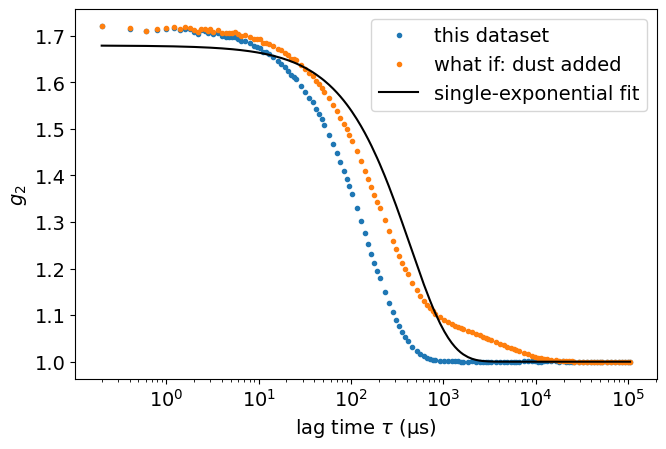

Gamma = 1148 (clean 3386) per second
reduced chi-squared = 2168


In [9]:
plt.semilogx(tau * 1e6, d["g2"], "o", ms=3, label="this dataset")
plt.semilogx(tau * 1e6, dusty, "o", ms=3, label="what if: dust added")
plt.semilogx(tau * 1e6, g2_single(tau, *popt), "-", color="k", label="single-exponential fit")
plt.xlabel(r"lag time $\tau$ (μs)"); plt.ylabel(r"$g_2$"); plt.legend(); plt.show()
print(f"Gamma = {popt[1]:.0f} (clean {row['Gamma']:.0f}) per second")
print(f"reduced chi-squared = {chi2_reduced(tau, dusty, err, popt):.0f}")

**What you should see.** With one particle in a billion, at 30°, the orange curve falls later than the blue one, and has a long tail reaching past 1000 μs. The black fit misses it. $\Gamma$ drops from about 3390 s⁻¹ to about 1150 s⁻¹, and the reduced $\chi^2$ is about 2200.

**How to read it.** This one is easy to spot, because the fit fails badly. Now change `n_example` to `1e-10` and run both cells again. The two curves look almost the same by eye, but the reduced $\chi^2$ is about 12 at this angle. In real work you would only catch it by looking at $\chi^2$ or at the residuals.

**Common error.** `IndexError: single positional indexer is out-of-bounds`: `ANGLE` is not in the file. Use 30, 45, ..., 150.

**The open question:** so a fit can be misled. How wrong is the size, and does the test of diffusion warn us?

---
# Part D. The size, and the test of diffusion

## Step 9. The full analysis, as a function

**What this cell does and why.** We repeat the analysis of notebook 01 on the what-if curves at all nine angles. For each angle we get the apparent radius $R_\mathrm{app} = k_BTq^2/(6\pi\eta\Gamma)$. We also fit $\Gamma$ against $q^2$ with a free line, using **`np.polyfit(x, y, 1, w=..., cov=True)`**. Degree 1 is a straight line, `w` holds the weights 1/error, and `cov=True` also returns the covariance matrix for the uncertainties. It gives back the slope and the intercept, highest power first.

- **`clean.iterrows()`** runs through the rows of a table, giving a label (`_`, which we ignore) and the row.
- **`np.diag`** picks out the diagonal of a matrix.

In [10]:
def dust_analysis(n, R_dust):
    rows = []
    for _, row in clean.iterrows():
        d = df[df["angle_deg"] == row["angle_deg"]]; t, e = d["lag_time_s"].values, d["g2_err"].values
        y = with_dust(d, row, n, R_dust); popt, pcov = fit_single(t, y, e); q = row["q"]
        rows.append({"angle_deg": row["angle_deg"], "q": q, "share": dust_share(q, n, R_dust),
                     "Gamma": popt[1], "Gamma_err": np.sqrt(pcov[1, 1]),
                     "R_app_nm": KT_OVER_6PI_ETA * q**2 / popt[1], "chi2_red": chi2_reduced(t, y, e, popt)})
    return pd.DataFrame(rows)

**What you should see.** Nothing is printed. This cell only defines the function.

## Step 10. Change the dust yourself

**What this cell does and why.** This is the cell to play with. Change the two marked lines and press Shift+Enter. It prints the size from the line, the intercept and the full table, and draws $R_\mathrm{app}$ against angle.

**Try:** `dust_per_protein` = `0`, `1e-11`, `1e-10`, `3e-10`, `1e-9`, `1e-8`. Then, with `1e-10`, try `R_dust` = `30`, `50`, `200`.

`plt.axhline(y)` draws a horizontal line, and `plt.ylim(bottom=0)` starts the axis at zero.

Radius from the slope = 3.57 nm
Intercept = -182 +- 61 per second


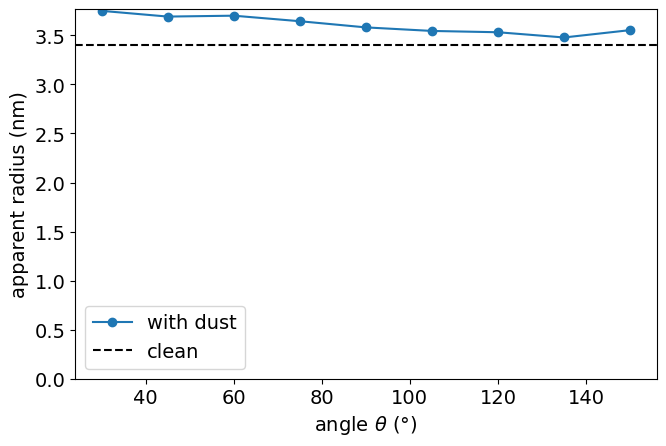

,angle_deg,q,share,Gamma,Gamma_err,R_app_nm,chi2_red
0,30.0,0.007,0.056,3056.091,5.372,3.750,12.283
1,45.0,0.010,0.050,6786.070,11.749,3.691,9.418
2,60.0,0.013,0.043,11557.007,15.168,3.701,6.059
3,75.0,0.016,0.037,17395.405,30.531,3.644,3.444
4,90.0,0.019,0.030,23883.271,43.910,3.581,2.446
5,105.0,0.021,0.025,30370.295,62.788,3.545,2.826
6,120.0,0.023,0.020,36327.169,79.752,3.532,0.984
7,135.0,0.024,0.017,41973.287,106.161,3.478,1.103
8,150.0,0.026,0.015,44917.277,147.259,3.553,1.635


In [11]:
dust_per_protein = 1e-10          # <-- CHANGE ME   dust particles per protein
R_dust = 100.0                    # <-- CHANGE ME   radius of the dust, in nm
t = dust_analysis(dust_per_protein, R_dust)
(slope, intercept), c = np.polyfit(t["q"]**2, t["Gamma"], 1, w=1 / t["Gamma_err"], cov=True)
print(f"Radius from the slope = {KT_OVER_6PI_ETA / slope:.2f} nm")
print(f"Intercept = {intercept:.0f} +- {np.sqrt(c[1, 1]):.0f} per second")
plt.plot(t["angle_deg"], t["R_app_nm"], "o-", label="with dust")
plt.axhline(R_PROTEIN, color="k", ls="--", label="clean"); plt.ylim(bottom=0)
plt.xlabel(r"angle $\theta$ (°)"); plt.ylabel("apparent radius (nm)"); plt.legend(); plt.show()
t.round(3)

**What you should see, with 100 nm dust**

| `dust_per_protein` | by mass, same density | radius from the slope | intercept (s⁻¹) | $R_\mathrm{app}$ at 30° | $R_\mathrm{app}$ at 150° | reduced $\chi^2$ at 30° | at 150° |
|---|---|---|---|---|---|---|---|
| 0 | | 3.41 nm | +23 | 3.4 nm | 3.5 nm | 1.1 | 1.2 |
| 1e-11 | 0.25 ppm | 3.42 nm | +3 | 3.4 nm | 3.5 nm | 1.3 | 1.3 |
| 1e-10 | 2.5 ppm | 3.57 nm | −182 | 3.75 nm | 3.55 nm | 12 | 1.6 |
| 3e-10 | 7.6 ppm | 3.96 nm | −569 | 4.8 nm | 3.8 nm | 160 | 6 |
| 1e-9 | 25 ppm | 7.3 nm | −513 | 10 nm | 4.9 nm | about 2200 | 174 |
| 1e-8 | 250 ppm | 86 nm | +11 | 77 nm | 86 nm | about 2100 | about 3700 |

**How to read it**

- **The apparent radius depends on angle.** It is larger at small angles. In a clean dilute sample it would not depend on angle at all, so this is the warning sign to look for.
- **The test of notebook 01 starts to fail.** The rates at small $q$ are pulled down the most, so the line tilts, and its intercept goes negative. Compare the clean value of $+23 \pm 25$ s⁻¹ with $-182 \pm 61$ s⁻¹.
- **A few parts per million by mass** already matter. At 2.5 ppm the radius is about 5 % too large, while the fits at the larger angles still look fine.
- **At $n = 10^{-8}$ the dust has taken over.** The apparent radius is now close to the dust's, at all angles. A student who only looks at one angle might report an 80 nm "protein".

**With $n = 10^{-10}$, changing the size of the dust**

| `R_dust` | radius from the slope | what happens |
|---|---|---|
| 30 nm | 3.4 nm | nothing visible: $R^6$ is merciless in both directions |
| 50 nm | 3.4 nm | still nothing visible |
| 100 nm | 3.6 nm | the table above |
| 200 nm | 89 nm | $R_\mathrm{app}$ is about 127 nm at 30°, 4.0 nm at 90° and 3.6 nm at 150° |

For 200 nm dust, the choice of angle decides everything: $P = 0.004$ at 150°.

**Common error.** `RuntimeError: Optimal parameters not found` can occur for extreme values of the knobs. Try a value in the table first.

**Question 2.** Why does dust make $R_\mathrm{app}$ *larger*, and why more so at small angles? Give two reasons.

<details>
<summary>Answer</summary>

Larger, because the dust decays slowly, and the fit is pulled towards a lower rate. More so at small angles because (1) the form factor P(qR_d) is closest to 1 at small q, so the dust's share of the light is largest there, and (2) the protein's rate is lowest at small q, while the correlator's weights favour the long-lag tail, where the dust sits.

</details>

**Question 3.** A colleague measures at 90° only, gets $R_h$ = 3.6 nm with a good-looking fit, and says the result is fine, since it's in the literature range of 3.3 to 4.3 nm. What would you ask them to do?

<details>
<summary>Answer</summary>

Measure at several angles, and check for an angle dependence of the apparent radius. Check that the intercept of Γ against q² is zero. Then filter or centrifuge the sample again and repeat. A wide literature range is partly a warning: some of that spread may come from aggregates, so agreement with it isn't evidence that the sample is clean.

</details>

**The open question:** how much dust is $10^{-10}$ in real terms?

---
# Part E. How much dust is that?

## Step 11. Count the particles

**What this cell does and why.** One ml of a 1 mg/ml solution holds $10^{-3}$ g of protein. Divide by the molar mass to get moles, and multiply by Avogadro's number to get molecules. Then one part in ten billion is a number of dust particles per ml.

The mass fraction, for equal density, is $n(R_d/R_p)^3$, because mass goes as volume.

**A typical scattering volume**, the volume that both the laser and the detector see, is of the order of 1 nanolitre: a region about 100 μm across. 1 nl = 10⁻⁶ ml. This is a round number for illustration.

In [12]:
proteins_per_ml = C_MG_ML * 1e-3 / M_DA * 6.022e23
n = 1e-10                                                  # <-- CHANGE ME   dust per protein
print(f"Proteins per ml: {proteins_per_ml:.1e}")
print(f"Dust particles per ml: {n * proteins_per_ml:.1e}")
print(f"Dust particles in 1 nl: {n * proteins_per_ml * 1e-6:.1f}")
print(f"Mass fraction: {n * (100 / R_PROTEIN)**3 * 1e6:.1f} parts per million")

Proteins per ml: 9.1e+15
Dust particles per ml: 9.1e+05
Dust particles in 1 nl: 0.9
Mass fraction: 2.5 parts per million


**What you should see.** About $9\times10^{15}$ proteins per ml, $9\times10^{5}$ dust particles per ml, **about one dust particle in the scattering volume**, and a mass fraction of 2.5 parts per million.

**How to read it: this is the real nuance.** So on average there's about one dust particle in the beam. It diffuses in and out. So in the lab, dust doesn't appear as a steady share as in our model. It appears as **bursts**: the count rate suddenly jumps while a particle crosses the beam. That is why people look at the intensity trace, and not only at $g_2$.

**What people do in the lab**

| Step | Why it helps |
|---|---|
| Filter the solution, with a pore size chosen for the sample | removes particles larger than the pores; a 0.2 μm filter stops particles of radius above about 100 nm |
| Centrifuge the sample | large particles sediment fastest |
| Clean the cuvette, for example with filtered solvent | most dust comes from the cell and the air, not from the protein |
| Watch the count-rate trace | a sudden burst means a large particle in the beam |
| Take many short runs and discard the ones with bursts | keeps the clean stretches, but be careful: this can also hide a real population, so report what was done |
| Measure at several angles | $R_\mathrm{app}$ independent of angle, and a zero intercept, are your evidence of a clean sample |
| Prefer larger angles for small proteins | dust is suppressed by its form factor there |

**Question 4.** The rejection of runs with bursts removes dust. Why might it also remove something you care about?

<details>
<summary>Answer</summary>

Real aggregates of the protein behave just like dust. If the question is whether a protein aggregates, for example before gelation, then those bursts and that slow tail are the signal. So decide first what the question is, and report the rejection criterion. For a gel-forming system in particular, the growth of large clusters is the science.

</details>

---
# What you have done

1. **Part A:** the clean analysis gives $R_h = 3.40$ nm. *How much does dust scatter?*
2. **Part B:** a 100 nm particle scatters like $6.5\times10^{8}$ proteins, less at large angles. *What does that do to a curve?*
3. **Part C:** a slow tail and a poor fit, sometimes visible only in $\chi^2$. *How wrong is the size?*
4. **Part D:** a few parts per million by mass shift $R_h$ by about 5 %, make it depend on angle, and turn the intercept negative. A hundred times more, and you measure the dust and not the protein. *How much dust is that?*
5. **Part E:** about one particle in the scattering volume. In the lab this appears as bursts, and it's why samples get filtered.

**The message to carry to your own samples.** Always measure at more than one angle. A radius that changes with angle, or a non-zero intercept, is telling you something, even when each single fit looks fine.

---
# Bonus exercises

*For those with time or Python experience.*

**Exercise 1: rescue the protein.** Fit a sum of two exponentials to the what-if curve at 30° with $n=10^{-9}$. Do you get the protein's rate back? And the dust's share?

<details>
<summary>Answer</summary>

```python
def g2_two(t, beta, A, G1, G2):
    return 1 + beta * (A * np.exp(-G1 * t) + (1 - A) * np.exp(-G2 * t))**2
row = clean[clean["angle_deg"] == 30].iloc[0]
d = df[df["angle_deg"] == 30]; t, e = d["lag_time_s"].values, d["g2_err"].values
y = with_dust(d, row, 1e-9, 100.0)
p, _ = curve_fit(g2_two, t, y, p0=[row["beta"], 0.5, row["Gamma"], row["Gamma"] / 20], sigma=e,
                 absolute_sigma=True, bounds=([0, 0, 0, 0], [2, 1, np.inf, np.inf]))
print(p, "clean Gamma:", row["Gamma"], "dust share:", dust_share(row["q"], 1e-9, 100.0))
```

You should recover the rate of the protein to within a few percent, with a share near 0.37 for the slow part. It works here because the two rates differ by a factor of 30. Be careful in general: as notebook 02 notes, fitting sums of exponentials is ill-conditioned, and two rates that are close can't be told apart.

</details>

**Exercise 2: the shape of the line.** With $n=10^{-9}$, plot $\Gamma$ against $q^2$ and the clean line. Is it still a straight line?

<details>
<summary>Answer</summary>

```python
t2 = dust_analysis(1e-9, 100.0)
plt.plot(t2["q"]**2, t2["Gamma"], "o", label="with dust")
plt.plot(clean["q"]**2, clean["Gamma"], "s", label="clean")
plt.xlabel(r"$q^2$ (nm$^{-2}$)"); plt.ylabel(r"$\Gamma$ (s$^{-1}$)"); plt.legend(); plt.show()
print(t2["Gamma"].round(0).tolist())
```

The points no longer lie on one line through zero. They fall far below the clean rates everywhere, by a factor of about three at small q and about 1.4 at large q. This is the failure of the line test mentioned in the lecture, typical of a mixture whose slow species fades out at large q.

</details>

**Exercise 3: the threshold.** Find the value of `dust_per_protein` at which the radius from the slope is 10 % too large. Is the reduced $\chi^2$ at 90° still near 1 there?

<details>
<summary>Answer</summary>

```python
for n_try in [1e-10, 1.5e-10, 2e-10, 3e-10]:
    t3 = dust_analysis(n_try, 100.0)
    slope3 = np.polyfit(t3["q"]**2, t3["Gamma"], 1, w=1 / t3["Gamma_err"])[0]
    print(n_try, round(KT_OVER_6PI_ETA / slope3, 2), round(t3["chi2_red"].iloc[4], 1))
```

The radius reaches about 3.75 nm, 10 % too large, near n = 2 × 10⁻¹⁰. The reduced χ² at 90° is then clearly above 1, about 8, and about 3 at 150°. So look at every angle, and look at χ².

</details>